# 05 · Evaluation and comparison

All models are refit on the full training split with the hyper-parameters chosen on the validation split (notebooks 02–04) and evaluated once on the test split.

**Protocol.** Per-user temporal split (last 20% of each user's ratings = test). For ranking, every movie the user has not rated in train is a candidate; test movies rated ≥ 4 are *relevant*. Metrics are averaged over users with at least one relevant test movie. RMSE is computed on all test ratings.

In [1]:
import sys, json
from pathlib import Path
sys.path.append(str(Path.cwd().parent))
import numpy as np, pandas as pd, matplotlib.pyplot as plt
pd.set_option("display.precision", 4); pd.set_option("display.width", 140)
RESULTS = Path("../results"); RESULTS.mkdir(exist_ok=True)

def save_params(name, params):
    path = RESULTS / "best_params.json"
    allp = json.loads(path.read_text()) if path.exists() else {}
    allp[name] = {k: (v.item() if hasattr(v, "item") else v) for k, v in params.items()}
    path.write_text(json.dumps(allp, indent=2))

In [2]:
from src.data import load_ratings, load_movies, temporal_user_split
ratings, movies = load_ratings(), load_movies()
train, test = temporal_user_split(ratings, test_frac=0.2)        # final evaluation
train_in, valid = temporal_user_split(train, test_frac=0.2)      # hyper-parameter tuning only
title = movies.set_index("item_idx")["title"]
print(f"train={len(train)} test={len(test)} | train_in={len(train_in)} valid={len(valid)}")

train=80000 test=20000 | train_in=64005 valid=15995


In [3]:
from src.models import PopularityRecommender, ItemKNNRecommender, ImplicitALSRecommender, ExplicitALSRecommender
from src.evaluation import evaluate_ranking, evaluate_rmse, recommend_top_k
P = json.loads((RESULTS / "best_params.json").read_text())   # produced by notebooks 02-04
P

{'popularity_ranking': {'method': 'count', 'm': 5},
 'popularity_rating': {'method': 'bayesian', 'm': 1.0},
 'itemknn_ranking': {'k': 1682, 'centered': False, 'weighting': 'rating'},
 'itemknn_rating': {'k': 20, 'centered': True},
 'ials': {'factors': 64,
  'regularization': 5.0,
  'alpha': 0.1,
  'iterations': 15},
 'eals': {'factors': 50, 'regularization': 0.15, 'iterations': 15}}

In [4]:
def build(name):
    return {
        "Popularity":   lambda: PopularityRecommender(**P["popularity_ranking"]),
        "ItemKNN":      lambda: ItemKNNRecommender(**P["itemknn_ranking"]),
        "ALS (implicit)": lambda: ImplicitALSRecommender(**P["ials"]),
        "ALS (explicit)": lambda: ExplicitALSRecommender(**P["eals"]),
    }[name]()

def build_rating(name):
    return {
        "Popularity":   lambda: PopularityRecommender(**P["popularity_rating"]),
        "ItemKNN":      lambda: ItemKNNRecommender(**P["itemknn_rating"]),
        "ALS (explicit)": lambda: ExplicitALSRecommender(**P["eals"]),
    }[name]()

NAMES = ["Popularity", "ItemKNN", "ALS (implicit)", "ALS (explicit)"]
KS = (5, 10, 20, 50)
rank_models = {n: build(n).fit(train) for n in NAMES}
rate_models = {n: build_rating(n).fit(train) for n in ["Popularity", "ItemKNN", "ALS (explicit)"]}
pop_fallback = rank_models["Popularity"]

/usr/local/lib/python3.13/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


## 1. Main comparison (K = 10)

In [5]:
rows, per_user = {}, {}
for n, m in rank_models.items():
    s, pu = evaluate_ranking(m, train, test, ks=KS, fallback=pop_fallback, per_user=True)
    rows[n], per_user[n] = s, pu
for n, m in rate_models.items():
    rows[n]["rmse"] = evaluate_rmse(m, test)
full = pd.DataFrame(rows).T
main = full[["rmse", "precision@10", "recall@10", "ndcg@10", "coverage@50"]]
main.to_csv(RESULTS / "comparison_main.csv"); full.to_csv(RESULTS / "comparison_all_k.csv")
main

,rmse,precision@10,recall@10,ndcg@10,coverage@50
Popularity,1.0688,0.0726,0.0722,0.0909,0.1237
ItemKNN,1.0215,0.1221,0.1402,0.1651,0.2574
ALS (implicit),NaN,0.1295,0.1532,0.1744,0.3841
ALS (explicit),0.9773,0.0498,0.0448,0.0576,0.3490


`rmse` is empty for implicit ALS because it does not predict ratings. `coverage@50` is the share of the 1,682 movies that appear in at least one user's top-50.

### Rating prediction vs. ranking

* **RMSE** measures how close predicted stars are to the true stars *on movies the user actually rated*. It is dominated by the bulk of 3–4 star ratings and says nothing about movies the user never watched.
* **Precision/Recall/NDCG@K** measure whether the movies the user goes on to watch and like appear at the top of a list built from the *whole catalogue*. This is what a recommender is actually used for, and it depends on modelling *which* movies a user will watch, not only how much they will like them.

A model can be good at one and poor at the other: the explicit ALS model is trained only on observed ratings, so for an unseen obscure movie it can predict a high rating with no evidence that the user would ever choose it. Compare its RMSE and its NDCG in the table above.

## 2. Effect of K

,Popularity,ItemKNN,ALS (implicit),ALS (explicit)
precision@5,0.0751,0.1430,0.1539,0.0514
precision@10,0.0726,0.1221,0.1295,0.0498
precision@20,0.0623,0.0970,0.1062,0.0409
precision@50,0.0507,0.0682,0.0740,0.0318
recall@5,0.0391,0.0837,0.0900,0.0248
recall@10,0.0722,0.1402,0.1532,0.0448
recall@20,0.1193,0.2176,0.2459,0.0720
recall@50,0.2411,0.3700,0.4150,0.1386
ndcg@5,0.0854,0.1626,0.1715,0.0547
ndcg@10,0.0909,0.1651,0.1744,0.0576


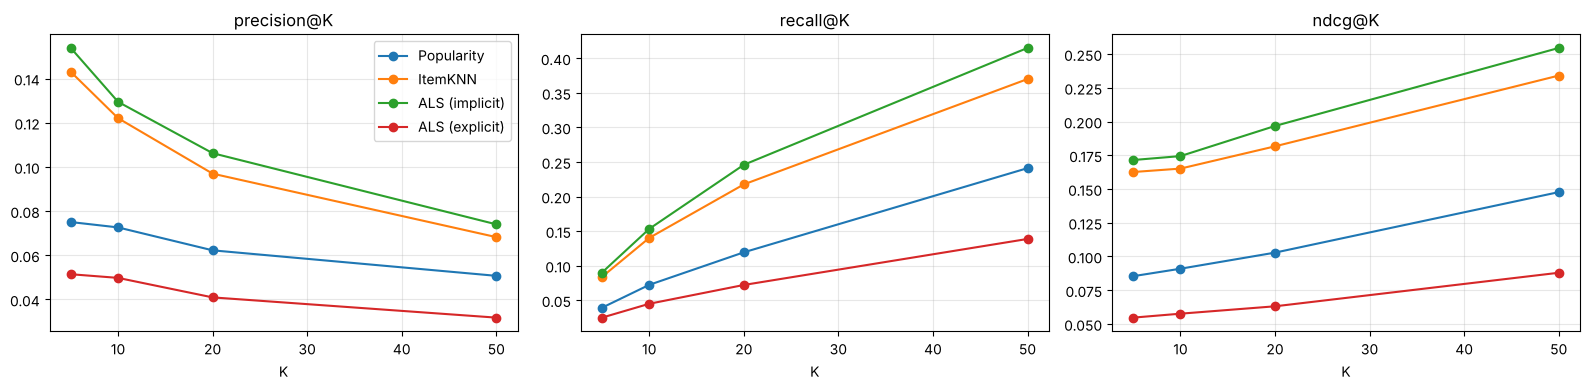

In [6]:
fig, ax = plt.subplots(1, 3, figsize=(16, 4))
for j, metric in enumerate(["precision", "recall", "ndcg"]):
    for n in NAMES:
        ax[j].plot(KS, [full.loc[n, f"{metric}@{k}"] for k in KS], marker="o", label=n)
    ax[j].set_title(f"{metric}@K"); ax[j].set_xlabel("K"); ax[j].grid(alpha=.3)
ax[0].legend(); plt.tight_layout()
full[[f"{m}@{k}" for m in ["precision", "recall", "ndcg"] for k in KS]].T

## 3. Effect of the number of training interactions

Test users are grouped into quartiles of their number of training ratings.

In [7]:
n_train = train.groupby("user_idx").size().rename("n_train")
bins = pd.qcut(n_train, 4)
df = pd.DataFrame({n: per_user[n]["ndcg@10"] for n in NAMES}).join(bins)
ndcg_by = df.groupby("n_train", observed=True).mean()
ndcg_by.insert(0, "users", df.groupby("n_train", observed=True).size())

test_b = test.assign(bucket=test.user_idx.map(bins))
rmse_by = {}
for n, m in rate_models.items():
    pred = m.predict(test_b.user_idx.values, test_b.item_idx.values)
    rmse_by[n] = test_b.assign(se=(pred - test_b.rating) ** 2).groupby("bucket", observed=True).se.mean() ** .5
rmse_by = pd.DataFrame(rmse_by)
ndcg_by.to_csv(RESULTS / "ndcg_by_activity.csv"); rmse_by.to_csv(RESULTS / "rmse_by_activity.csv")
display(ndcg_by); display(rmse_by)

,users,Popularity,ItemKNN,ALS (implicit),ALS (explicit)
n_train,,,,,
"(15.999, 26.0]",219,0.0643,0.1345,0.1461,0.0277
"(26.0, 52.0]",225,0.0598,0.1507,0.1562,0.0424
"(52.0, 118.0]",230,0.1141,0.1710,0.1701,0.0728
"(118.0, 590.0]",232,0.1233,0.2022,0.2231,0.0855


,Popularity,ItemKNN,ALS (explicit)
bucket,,,
"(15.999, 26.0]",1.1292,1.1007,1.0576
"(26.0, 52.0]",1.0637,1.0365,0.9885
"(52.0, 118.0]",1.0570,1.0335,0.9892
"(118.0, 590.0]",1.0679,1.0048,0.9613


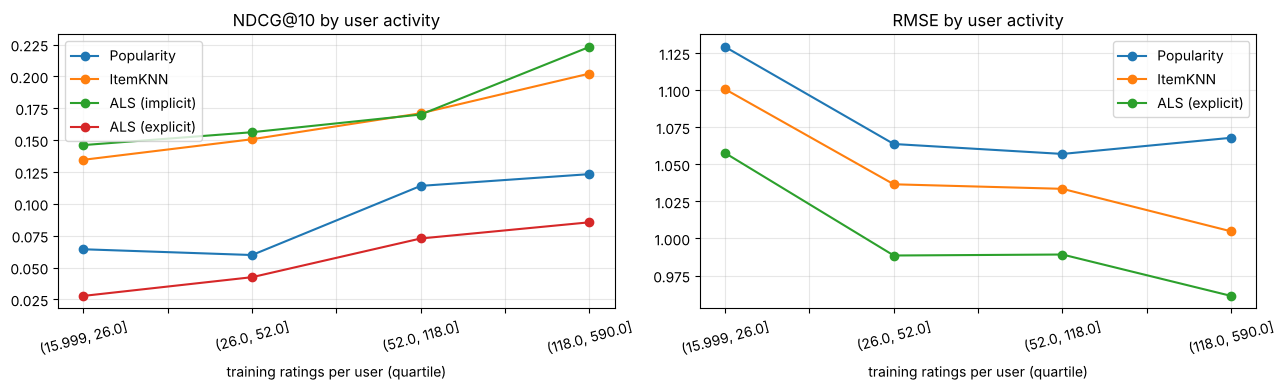

In [8]:
fig, ax = plt.subplots(1, 2, figsize=(13, 4))
ndcg_by.drop(columns="users").plot(marker="o", ax=ax[0], title="NDCG@10 by user activity")
rmse_by.plot(marker="o", ax=ax[1], title="RMSE by user activity")
for a in ax: a.set_xlabel("training ratings per user (quartile)"); a.grid(alpha=.3); a.tick_params(axis="x", rotation=15)
plt.tight_layout()

Note: test-set size also grows with activity (20% of a user's ratings), so Precision@K rises mechanically with activity; NDCG and Recall are normalised by the number of relevant items and are easier to compare across groups.

## 4. Cold-start users

Simulation: 200 random users keep only their **first n** training ratings (n = 0, 1, 2, 5, 10, 15); all other users keep their full training history. Every model is retrained on this reduced training set and evaluated on the same test ratings of the 200 users. For n = 0 the personalised models have no signal and fall back to the popularity list (an explicit, simple hybrid).

In [9]:
rng = np.random.default_rng(0)
cold_users = rng.choice(train.user_idx.unique(), size=200, replace=False)
is_cold = train.user_idx.isin(cold_users)
order = train.sort_values(["user_idx", "timestamp", "item_idx"])
rows = []
for n_hist in [0, 1, 2, 5, 10, 15]:
    keep = order[order.user_idx.isin(cold_users)].groupby("user_idx").head(n_hist)
    tr = pd.concat([train[~is_cold], keep])
    fb = build("Popularity").fit(tr)
    for n in NAMES:
        m = fb if n == "Popularity" else build(n).fit(tr)
        s = evaluate_ranking(m, tr, test, ks=(10,), fallback=fb, users=cold_users)
        row = {"n_history": n_hist, "model": n, "ndcg@10": s["ndcg@10"], "recall@10": s["recall@10"],
               "precision@10": s["precision@10"]}
        if n in rate_models:
            row["rmse"] = evaluate_rmse(build_rating(n).fit(tr), test[test.user_idx.isin(cold_users)])
        rows.append(row)
cold = pd.DataFrame(rows)
cold.to_csv(RESULTS / "cold_start.csv", index=False)
cold.pivot(index="n_history", columns="model", values="ndcg@10")

model,ALS (explicit),ALS (implicit),ItemKNN,Popularity
n_history,,,,
0,0.0483,0.0483,0.0483,0.0483
1,0.0398,0.0463,0.0415,0.0505
2,0.0408,0.0529,0.0508,0.0516
5,0.0411,0.0531,0.0516,0.0548
10,0.0417,0.0653,0.0653,0.0607
15,0.0386,0.0800,0.0791,0.0652


model,ALS (explicit),ItemKNN,Popularity
n_history,,,
0,1.0681,1.1998,1.0403
1,1.0686,1.5728,1.0402
2,1.0725,1.5761,1.0403
5,1.0671,1.4300,1.0403
10,1.0744,1.3236,1.0403
15,1.0660,1.2561,1.0399


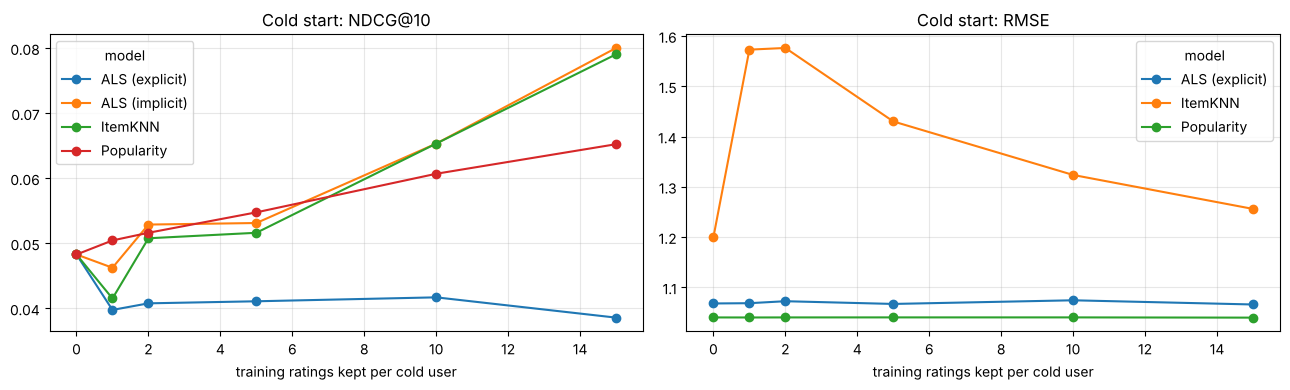

In [10]:
display(cold.pivot(index="n_history", columns="model", values="rmse").dropna(axis=1, how="all"))
fig, ax = plt.subplots(1, 2, figsize=(13, 4))
cold.pivot(index="n_history", columns="model", values="ndcg@10").plot(marker="o", ax=ax[0], title="Cold start: NDCG@10")
cold.pivot(index="n_history", columns="model", values="rmse").dropna(axis=1, how="all").plot(marker="o", ax=ax[1], title="Cold start: RMSE")
for a in ax: a.set_xlabel("training ratings kept per cold user"); a.grid(alpha=.3)
plt.tight_layout()

## 5. Robustness check: strict global time split

Train on all ratings before the 80th percentile of timestamps, test on the rest. No future information from any user is available at training time. Users who appear only after the cut-off are cold-start and receive the popularity list. Hyper-parameters are kept from the per-user validation split (not re-tuned).

In [11]:
from src.data import global_temporal_split
g_train, g_test = global_temporal_split(ratings, 0.2)
print(f"train={len(g_train)}, test={len(g_test)}, test users={g_test.user_idx.nunique()}, "
      f"of which unseen in train={len(set(g_test.user_idx) - set(g_train.user_idx))}")
g_fb = build("Popularity").fit(g_train)
g_rows = {}
for n in NAMES:
    m = g_fb if n == "Popularity" else build(n).fit(g_train)
    g_rows[n] = evaluate_ranking(m, g_train, g_test, ks=(10,), fallback=g_fb)
for n in rate_models:
    g_rows[n]["rmse"] = evaluate_rmse(build_rating(n).fit(g_train), g_test)
glob = pd.DataFrame(g_rows).T[["rmse", "precision@10", "recall@10", "ndcg@10", "n_users"]]
glob.to_csv(RESULTS / "comparison_global_split.csv")
glob

train=80003, test=19997, test users=301, of which unseen in train=192


,rmse,precision@10,recall@10,ndcg@10,n_users
Popularity,1.0306,0.2297,0.0853,0.2541,290.0
ItemKNN,1.1128,0.2352,0.0786,0.2570,290.0
ALS (implicit),NaN,0.2345,0.0885,0.2582,290.0
ALS (explicit),1.0228,0.2217,0.0876,0.2450,290.0


## 6. Example recommendations

✓ = the movie is in the user's test set with rating ≥ 4.

In [12]:
counts = train.groupby("user_idx").size()
examples = [int(counts.idxmin()), int((counts - counts.median()).abs().idxmin()), int(counts.idxmax())]
for u in examples:
    liked = set(test[(test.user_idx == u) & (test.rating >= 4)].item_idx)
    hist = train[train.user_idx == u].sort_values(["rating", "timestamp"], ascending=False)
    print(f"\n=== user {u + 1}: {counts[u]} training ratings, {len(liked)} liked test movies")
    print("liked in train:", "; ".join(title[hist.item_idx.head(5)]))
    table = {}
    for n in ["Popularity", "ItemKNN", "ALS (implicit)"]:
        rec = recommend_top_k(rank_models[n], train, [u], 10)[0]
        table[n] = [("✓ " if i in liked else "  ") + title[i][:38] for i in rec]
    print(pd.DataFrame(table, index=range(1, 11)).to_string())


=== user 19: 16 training ratings, 2 liked test movies
liked in train: Babe (1995); Get Shorty (1995); Fish Called Wanda, A (1988); Groundhog Day (1993); Crash (1996)
                          Popularity                                   ItemKNN                 ALS (implicit)
1                   Star Wars (1977)                          Star Wars (1977)           Air Force One (1997)
2                       Fargo (1996)                 Back to the Future (1985)               Game, The (1997)
3          Return of the Jedi (1983)                       Pulp Fiction (1994)       Good Will Hunting (1997)
4        English Patient, The (1996)                 Return of the Jedi (1983)         Full Monty, The (1997)
5                   Toy Story (1995)            Raiders of the Lost Ark (1981)       Conspiracy Theory (1997)
6               Air Force One (1997)           Empire Strikes Back, The (1980)       L.A. Confidential (1997)
7      Independence Day (ID4) (1996)          Silence of the La